# 06 - Subgrafos com LangGraph

Caso prático: um **coordenador** recebe um tema e delega o trabalho a três agentes especializados. Cada agente é um **subgrafo**, ou seja, um grafo compilado que roda dentro de um nó do grafo principal.

Fluxo:

```
START → planejar → pesquisa → analise → redacao → END
        (coordenador)  (subgrafo)  (subgrafo)  (subgrafo)

pesquisa: START → buscar → resumir → END
analise:  START → extrair_pontos → avaliar → END
redacao:  START → rascunhar → revisar → END
```

- **Subgrafo**: um `StateGraph` compilado com o próprio estado. Ele é usado como função: recebe um dicionário e devolve um dicionário.
- **Estado isolado**: cada subgrafo tem as chaves de que precisa. O grafo principal só enxerga o que o nó de delegação devolve.
- **Nó de delegação**: a função que chama `subgrafo.invoke(...)` e converte o estado do pai para o do filho, e o resultado de volta.

## 1. Configuração

A chave e o modelo vêm do `.env` na raiz do projeto, como nos outros notebooks.

In [1]:
import operator
import os
from typing import Annotated, TypedDict

from dotenv import find_dotenv, load_dotenv
from IPython.display import Markdown, display
from langchain_core.messages import HumanMessage, SystemMessage
from langchain_openai import ChatOpenAI
from langgraph.graph import END, START, StateGraph

from IPython.display import Markdown, display
from IPython.display import Image


load_dotenv(find_dotenv())

llm = ChatOpenAI(
    model=os.getenv("OPENAI_MODEL", "gpt-5-mini"),
    api_key=os.getenv("OPENAI_API_KEY"),
)


def pedir(instrucao: str, conteudo: str) -> str:
    return llm.invoke([SystemMessage(content=instrucao), HumanMessage(content=conteudo)]).content

## 2. Fontes simuladas

A pesquisa usaria uma API ou um buscador. Para o notebook rodar sem internet, as fontes são textos fictícios guardados num dicionário.

In [2]:
FONTES_SIMULADAS = {
    "energia solar residencial no Brasil": [
        "Relatório A: o número de sistemas residenciais conectados à rede cresceu em todos os anos da última década.",
        "Relatório B: o custo de instalação caiu, mas o financiamento ainda é o principal obstáculo para famílias de renda média.",
        "Relatório C: a compensação de energia permite abater a conta mensal, o que atrai quem tem telhado disponível.",
    ],
}

## 3. Subgrafo de pesquisa

Estado próprio: `tema`, `fontes` e `resumo`. Ele não conhece as outras chaves do grafo principal.

In [3]:
class PesquisaEstado(TypedDict):
    tema: str
    fontes: list[str]
    resumo: str


def buscar(estado: PesquisaEstado) -> dict:
    return {"fontes": FONTES_SIMULADAS.get(estado["tema"], [])}


def resumir(estado: PesquisaEstado) -> dict:
    fontes = "\n".join(estado["fontes"]) or "Nenhuma fonte encontrada."
    resumo = pedir(
        "Você é um pesquisador. Resuma as fontes em até 3 tópicos, em português. "
        "Use apenas o que está nas fontes.",
        f"Tema: {estado['tema']}\nFontes:\n{fontes}",
    )
    return {"resumo": resumo}


grafo_pesquisa = StateGraph(PesquisaEstado)
grafo_pesquisa.add_node("buscar", buscar)
grafo_pesquisa.add_node("resumir", resumir)
grafo_pesquisa.add_edge(START, "buscar")
grafo_pesquisa.add_edge("buscar", "resumir")
grafo_pesquisa.add_edge("resumir", END)
subgrafo_pesquisa = grafo_pesquisa.compile()

## 4. Subgrafo de análise

Estado próprio: `resumo`, `pontos` e `analise`. Recebe o resumo da pesquisa e produz uma conclusão.

In [4]:
class AnaliseEstado(TypedDict):
    resumo: str
    pontos: str
    analise: str


def extrair_pontos(estado: AnaliseEstado) -> dict:
    pontos = pedir(
        "Você extrai os 3 pontos mais importantes de um resumo de pesquisa. Responda em português, em lista curta.",
        estado["resumo"],
    )
    return {"pontos": pontos}


def avaliar(estado: AnaliseEstado) -> dict:
    analise = pedir(
        "Você é um analista. Com base nos pontos, escreva uma conclusão de 2 frases e um risco principal. "
        "Responda em português.",
        estado["pontos"],
    )
    return {"analise": analise}


grafo_analise = StateGraph(AnaliseEstado)
grafo_analise.add_node("extrair_pontos", extrair_pontos)
grafo_analise.add_node("avaliar", avaliar)
grafo_analise.add_edge(START, "extrair_pontos")
grafo_analise.add_edge("extrair_pontos", "avaliar")
grafo_analise.add_edge("avaliar", END)
subgrafo_analise = grafo_analise.compile()

## 5. Subgrafo de redação

Estado próprio: `briefing`, `analise`, `rascunho` e `texto`. O revisor pode corrigir o texto, mas não deve acrescentar fatos.

In [5]:
class RedacaoEstado(TypedDict):
    briefing: str
    analise: str
    rascunho: str
    texto: str


def rascunhar(estado: RedacaoEstado) -> dict:
    rascunho = pedir(
        "Você é redator. Escreva um texto de até 150 palavras, em português, para leitores não especialistas. "
        "Baseie-se somente na análise. Use o briefing apenas para o tom e o público.",
        f"Briefing: {estado['briefing']}\nAnálise: {estado['analise']}",
    )
    return {"rascunho": rascunho}


def revisar(estado: RedacaoEstado) -> dict:
    texto = pedir(
        "Revise o texto: corrija clareza e gramática. Não acrescente fatos novos.",
        estado["rascunho"],
    )
    return {"texto": texto}


grafo_redacao = StateGraph(RedacaoEstado)
grafo_redacao.add_node("rascunhar", rascunhar)
grafo_redacao.add_node("revisar", revisar)
grafo_redacao.add_edge(START, "rascunhar")
grafo_redacao.add_edge("rascunhar", "revisar")
grafo_redacao.add_edge("revisar", END)
subgrafo_redacao = grafo_redacao.compile()

## 6. Grafo do coordenador

O estado do coordenador tem as chaves que circulam entre os agentes, mais `etapas`. `etapas` usa um reducer (`operator.add`) para acumular o histórico de execução. Cada nó de delegação chama o subgrafo correspondente, passa só os campos que ele precisa e grava o resultado de volta.

In [6]:
class Estado(TypedDict):
    tema: str
    briefing: str
    resumo: str
    analise: str
    texto: str
    etapas: Annotated[list[str], operator.add]


def planejar(estado: Estado) -> dict:
    briefing = pedir(
        "Você coordena uma equipe com três agentes: pesquisa, análise e redação. "
        "Escreva um briefing curto, em português, com uma frase para cada agente sobre o foco dele e o tom do texto final. "
        "Não invente prazos, formatos, número de páginas ou entregas que não foram pedidos.",
        f"Tema: {estado['tema']}",
    )
    return {"briefing": briefing, "etapas": ["coordenador: briefing"]}


def delegar_pesquisa(estado: Estado) -> dict:
    resultado = subgrafo_pesquisa.invoke({"tema": estado["tema"], "fontes": [], "resumo": ""})
    return {"resumo": resultado["resumo"], "etapas": ["subgrafo pesquisa"]}


def delegar_analise(estado: Estado) -> dict:
    resultado = subgrafo_analise.invoke({"resumo": estado["resumo"], "pontos": "", "analise": ""})
    return {"analise": resultado["analise"], "etapas": ["subgrafo análise"]}


def delegar_redacao(estado: Estado) -> dict:
    resultado = subgrafo_redacao.invoke({
        "briefing": estado["briefing"],
        "analise": estado["analise"],
        "rascunho": "",
        "texto": "",
    })
    return {"texto": resultado["texto"], "etapas": ["subgrafo redação"]}


grafo = StateGraph(Estado)
grafo.add_node("planejar", planejar)
grafo.add_node("pesquisa", delegar_pesquisa)
grafo.add_node("analise", delegar_analise)
grafo.add_node("redacao", delegar_redacao)

grafo.add_edge(START, "planejar")
grafo.add_edge("planejar", "pesquisa")
grafo.add_edge("pesquisa", "analise")
grafo.add_edge("analise", "redacao")
grafo.add_edge("redacao", END)

app = grafo.compile()

## 7. Visualizando os subgrafos

`get_graph(xray=True)` expande os subgrafos no diagrama. Sem `xray`, cada subgrafo aparece como um único nó.

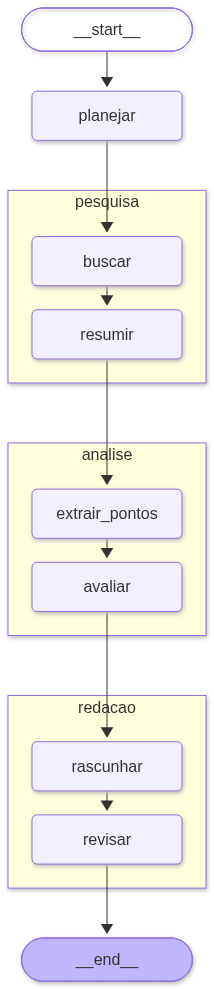

In [9]:
display(Image(app.get_graph(xray=True).draw_mermaid_png()))

## 8. Executando

O tema é o mesmo das fontes simuladas. O campo `etapas` mostra a ordem em que os agentes rodaram.

In [8]:
estado = app.invoke({"tema": "energia solar residencial no Brasil", "etapas": []})

linhas = [
    f"**Tema:** {estado['tema']}",
    "",
    f"**Briefing do coordenador:** {estado['briefing']}",
    "",
    f"**Etapas:** {' → '.join(estado['etapas'])}",
    "",
    "**Análise:**",
    estado["analise"],
    "",
    "**Texto final:**",
    estado["texto"],
]
display(Markdown("\n".join(linhas)))

**Tema:** energia solar residencial no Brasil

**Briefing do coordenador:** Pesquisa: Foque em reunir fontes atualizadas e verificáveis sobre energia solar residencial no Brasil — capacidade instalada, custos médios, regulamentação (ANEEL), incentivos regionais, opções de financiamento e dados de payback; tom do material: factual e objetivo para sustentar o texto final.  
Análise: Foque em interpretar e comparar os dados para apontar benefícios econômicos e ambientais, riscos, barreiras práticas e oportunidades por região e perfil de consumidor; tom: crítico, pragmático e orientado a decisões.  
Redação: Foque em transformar as conclusões em um texto claro e acessível para proprietários residenciais brasileiros, com explicações de processos, vantagens, custos e passos práticos para adoção; tom: didático, confiável e acessível.

**Etapas:** coordenador: briefing → subgrafo pesquisa → subgrafo análise → subgrafo redação

**Análise:**
A adoção residencial de sistemas conectados cresceu consistentemente na última década, impulsionada pela queda nos custos de instalação e por incentivos de compensação que reduzem a conta mensal para quem tem telhado disponível. Contudo, a persistência de barreiras de financiamento impede muitas famílias de renda média de acessar essas soluções, limitando a expansão equitativa do mercado. 

Risco principal: exclusão financeira — sem mecanismos de financiamento acessíveis, o crescimento continuará concentrado entre proprietários com capital e cobertura adequada, aprofundando desigualdades no acesso aos benefícios.

**Texto final:**
A energia solar residencial conectada à rede tem crescido na última década: a queda dos custos e os mecanismos de compensação reduzem a conta de quem tem telhado bem exposto. Economicamente, isso significa menor gasto mensal e recuperação do investimento ao longo do tempo; ambientalmente, reduz emissões locais.

O principal obstáculo é o financiamento. Sem linhas acessíveis, muitas famílias de renda média não conseguem instalar sistemas, concentrando os benefícios entre proprietários com capital ou cobertura adequada e gerando risco de exclusão financeira.

Passos práticos para quem pensa em adotar: verifique a insolação e o espaço disponível no telhado; solicite a instaladores simulações de geração, economia e prazo de retorno do investimento; compare orçamentos e opções de financiamento; confirme as regras locais de compensação e os possíveis incentivos. Para ampliar o acesso, são necessárias políticas públicas e instrumentos de crédito mais inclusivos.

## 9. Por que usar subgrafos

- **Estado isolado**: o subgrafo de pesquisa não vê `analise` nem `texto`. Isso reduz acoplamento entre os agentes.
- **Reutilização**: cada subgrafo pode ser testado sozinho, como fizemos na pesquisa, e reaproveitado em outro grafo.
- **Mapeamento explícito**: o nó de delegação decide o que entra e o que sai. Quando os nomes das chaves são iguais, dá para adicionar o subgrafo compilado direto como nó, mas aqui o mapeamento fica visível.
- **Histórico do pai**: `etapas` mostra o caminho percorrido sem expor o estado interno dos subgrafos.